# Gaming industry: what decides how many people are online at once?
Data Analytics for Managers using Python | Individual case-based assessment
Yash Sobti, 26PGDM095

## 1. Business problem

I picked the video game industry. Imagine I work in the live-ops team of a game publisher. Before every launch we have to decide how many servers to book. Total players is easy to forecast, but what actually breaks the servers is the number of people playing **at the same time** (peak concurrent players).

So my business question is:

**How much of a game's peak concurrent players can we explain using total players, Metacritic score, esports popularity, platform, genre and trending status? And does a better score change how many of the players are online together?**

If we can predict it reasonably well, the team can book servers from the player forecast instead of guessing. Booking too little means crashes and refunds, booking too much wastes money.

Dataset: *Gaming Industry Trends* from Kaggle (1,000 rows, 11 columns).

| Column | Type | Why it matters |
|---|---|---|
| Peak Concurrent Players | number | what I want to predict (server load) |
| Players (Millions) | number | total audience, my main predictor |
| Metacritic Score | number | quality of the game |
| Revenue (Millions $) | number | how much the game earned |
| Release Year | number | to see if older/newer games behave differently |
| Esports Popularity | Yes/No | competitive games may have everyone online together |
| Platform | category (6) | PC, consoles, mobile etc. |
| Genre | category (10) | different types of play sessions |
| Trending Status | category (3) | rising, stable or declining |
| Game Title, Developer | text | used for grouping and joins in SQL |

The dataset does not say what unit peak concurrent players is in. It is on the same scale as total players (millions), so I treat it as millions.

In [1]:
import os
import sqlite3
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import KFold

warnings.filterwarnings('ignore')

# works on Kaggle and on my laptop
for p in ['/kaggle/input/gaming-industry-trends-1000-rows/gaming_industry_trends.csv',
          '../data/gaming_industry_trends.csv', 'data/gaming_industry_trends.csv']:
    if os.path.exists(p):
        path = p
        break

figdir = '../outputs/figures' if os.path.exists('../outputs') else 'figures'
os.makedirs(figdir, exist_ok=True)

raw = pd.read_csv(path)
df = raw.copy()
df.columns = ['title', 'genre', 'platform', 'year', 'developer', 'revenue',
              'players', 'peak', 'meta', 'esports', 'trend']
print(df.shape)
df.head()

(1000, 11)


,title,genre,platform,year,developer,revenue,players,peak,meta,esports,trend
0,Neon Speed 5,Strategy,Xbox,2011,Capcom,52.28,77.99,21.44,69,No,Stable
1,Cyber Quest 5,Shooter,Mobile,2018,Bandai Namco,4345.97,65.28,11.22,72,No,Stable
2,Fantasy Rivals 1,Strategy,Xbox,2018,Microsoft,1278.29,160.09,48.40,51,Yes,Declining
3,Warzone Chronicles 5,Horror,Xbox,2002,Microsoft,361.26,98.14,32.96,91,No,Declining
4,Cyber Quest 4,RPG,PC,2018,EA,4549.27,199.47,58.39,74,No,Stable


## 2. Descriptive statistics

In [2]:
num_cols = ['revenue', 'players', 'peak', 'meta', 'year']
stats = df[num_cols].describe().T
stats['median'] = df[num_cols].median()
stats['skew'] = df[num_cols].skew()
stats[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'skew']].round(2)

,count,mean,median,std,min,25%,75%,max,skew
revenue,1000.0,2483.02,2476.13,1412.63,11.43,1276.19,3677.80,4999.79,0.03
players,1000.0,103.50,107.04,58.87,0.53,52.00,155.63,199.98,-0.10
peak,1000.0,31.60,26.40,23.02,0.11,12.97,46.02,96.62,0.73
meta,1000.0,74.99,76.00,14.62,50.00,62.00,87.00,100.00,-0.04
year,1000.0,2012.07,2012.00,7.03,2000.00,2006.00,2018.00,2024.00,-0.02


In [3]:
for col in ['genre', 'platform', 'developer', 'esports', 'trend']:
    print(df[col].value_counts())
    print()

genre
Action        122
Strategy      116
Sports        116
Fighting      103
Shooter       100
Horror         96
Racing         95
Adventure      87
Simulation     87
RPG            78
Name: count, dtype: int64

platform
PlayStation        175
PC                 174
Cross-Platform     168
Xbox               167
Mobile             158
Nintendo Switch    158
Name: count, dtype: int64

developer
Sony            120
Activision      109
Rockstar        107
Microsoft       106
Ubisoft         103
Capcom           96
Nintendo         96
EA               92
Square Enix      88
Bandai Namco     83
Name: count, dtype: int64

esports
Yes    507
No     493
Name: count, dtype: int64

trend
Stable       339
Rising       335
Declining    326
Name: count, dtype: int64



The averages are close to the middle of each range (for example Metacritic mean 75, median 76, and players mean 103, median 107), and skewness is close to zero for every variable except peak players (0.73), which has a longer tail of a few very big games. Peak players has a mean of about 32 million, much lower than total players, which makes sense because not everyone plays at the same time.

## 3. Exploratory data analysis

In [4]:
print('missing values:')
print(df.isnull().sum())
print()
print('duplicate rows:', df.duplicated().sum())
print('unique game titles:', df['title'].nunique())

missing values:
title        0
genre        0
platform     0
year         0
developer    0
revenue      0
players      0
peak         0
meta         0
esports      0
trend        0
dtype: int64

duplicate rows: 0
unique game titles: 50


In [5]:
# outliers using the 1.5 x IQR rule
for col in ['revenue', 'players', 'peak', 'meta']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n = ((df[col] < low) | (df[col] > high)).sum()
    print(col, '- outliers:', n)

revenue - outliers: 0
players - outliers: 0
peak - outliers: 2
meta - outliers: 0


In [6]:
df['peak_ratio'] = df['peak'] / df['players']   # share of players online together
print(df[['peak', 'players', 'revenue', 'meta', 'year']].corr().round(2))
print()
print('average peak/players ratio:', round(df['peak_ratio'].mean(), 3))
print()
print(df.groupby('esports')[['players', 'peak', 'revenue']].mean().round(1))
print()
print(df.groupby('platform')[['players', 'peak', 'revenue']].mean().round(1))

         peak  players  revenue  meta  year
peak     1.00     0.80    -0.03  0.02  0.01
players  0.80     1.00    -0.02 -0.01  0.01
revenue -0.03    -0.02     1.00  0.02  0.01
meta     0.02    -0.01     0.02  1.00  0.02
year     0.01     0.01     0.01  0.02  1.00

average peak/players ratio: 0.303

         players  peak  revenue
esports                        
No         104.4  32.0   2462.1
Yes        102.6  31.2   2503.4

                 players  peak  revenue
platform                               
Cross-Platform     108.1  33.5   2521.6
Mobile              98.7  31.3   2525.9
Nintendo Switch     95.1  28.1   2576.6
PC                 106.2  32.7   2450.1
PlayStation        105.2  30.2   2375.0
Xbox               106.8  33.7   2462.6


What I found:
- There are no missing values and no duplicate rows, so no cleaning was needed.
- Only 2 outliers show up, both in peak players (about 96 million, the top end). They look like genuine big games, not mistakes, so I kept them.
- Peak players and total players are strongly related (correlation 0.80). On average about 30% of players are online together.
- Revenue, Metacritic score and release year are almost uncorrelated with everything else.
- Group averages (esports, platform) are very close to each other.
- The same game title shows up many times (50 titles, 1,000 rows), so each row is a release record on one platform and year, not a unique game.

## 4. Visualisations

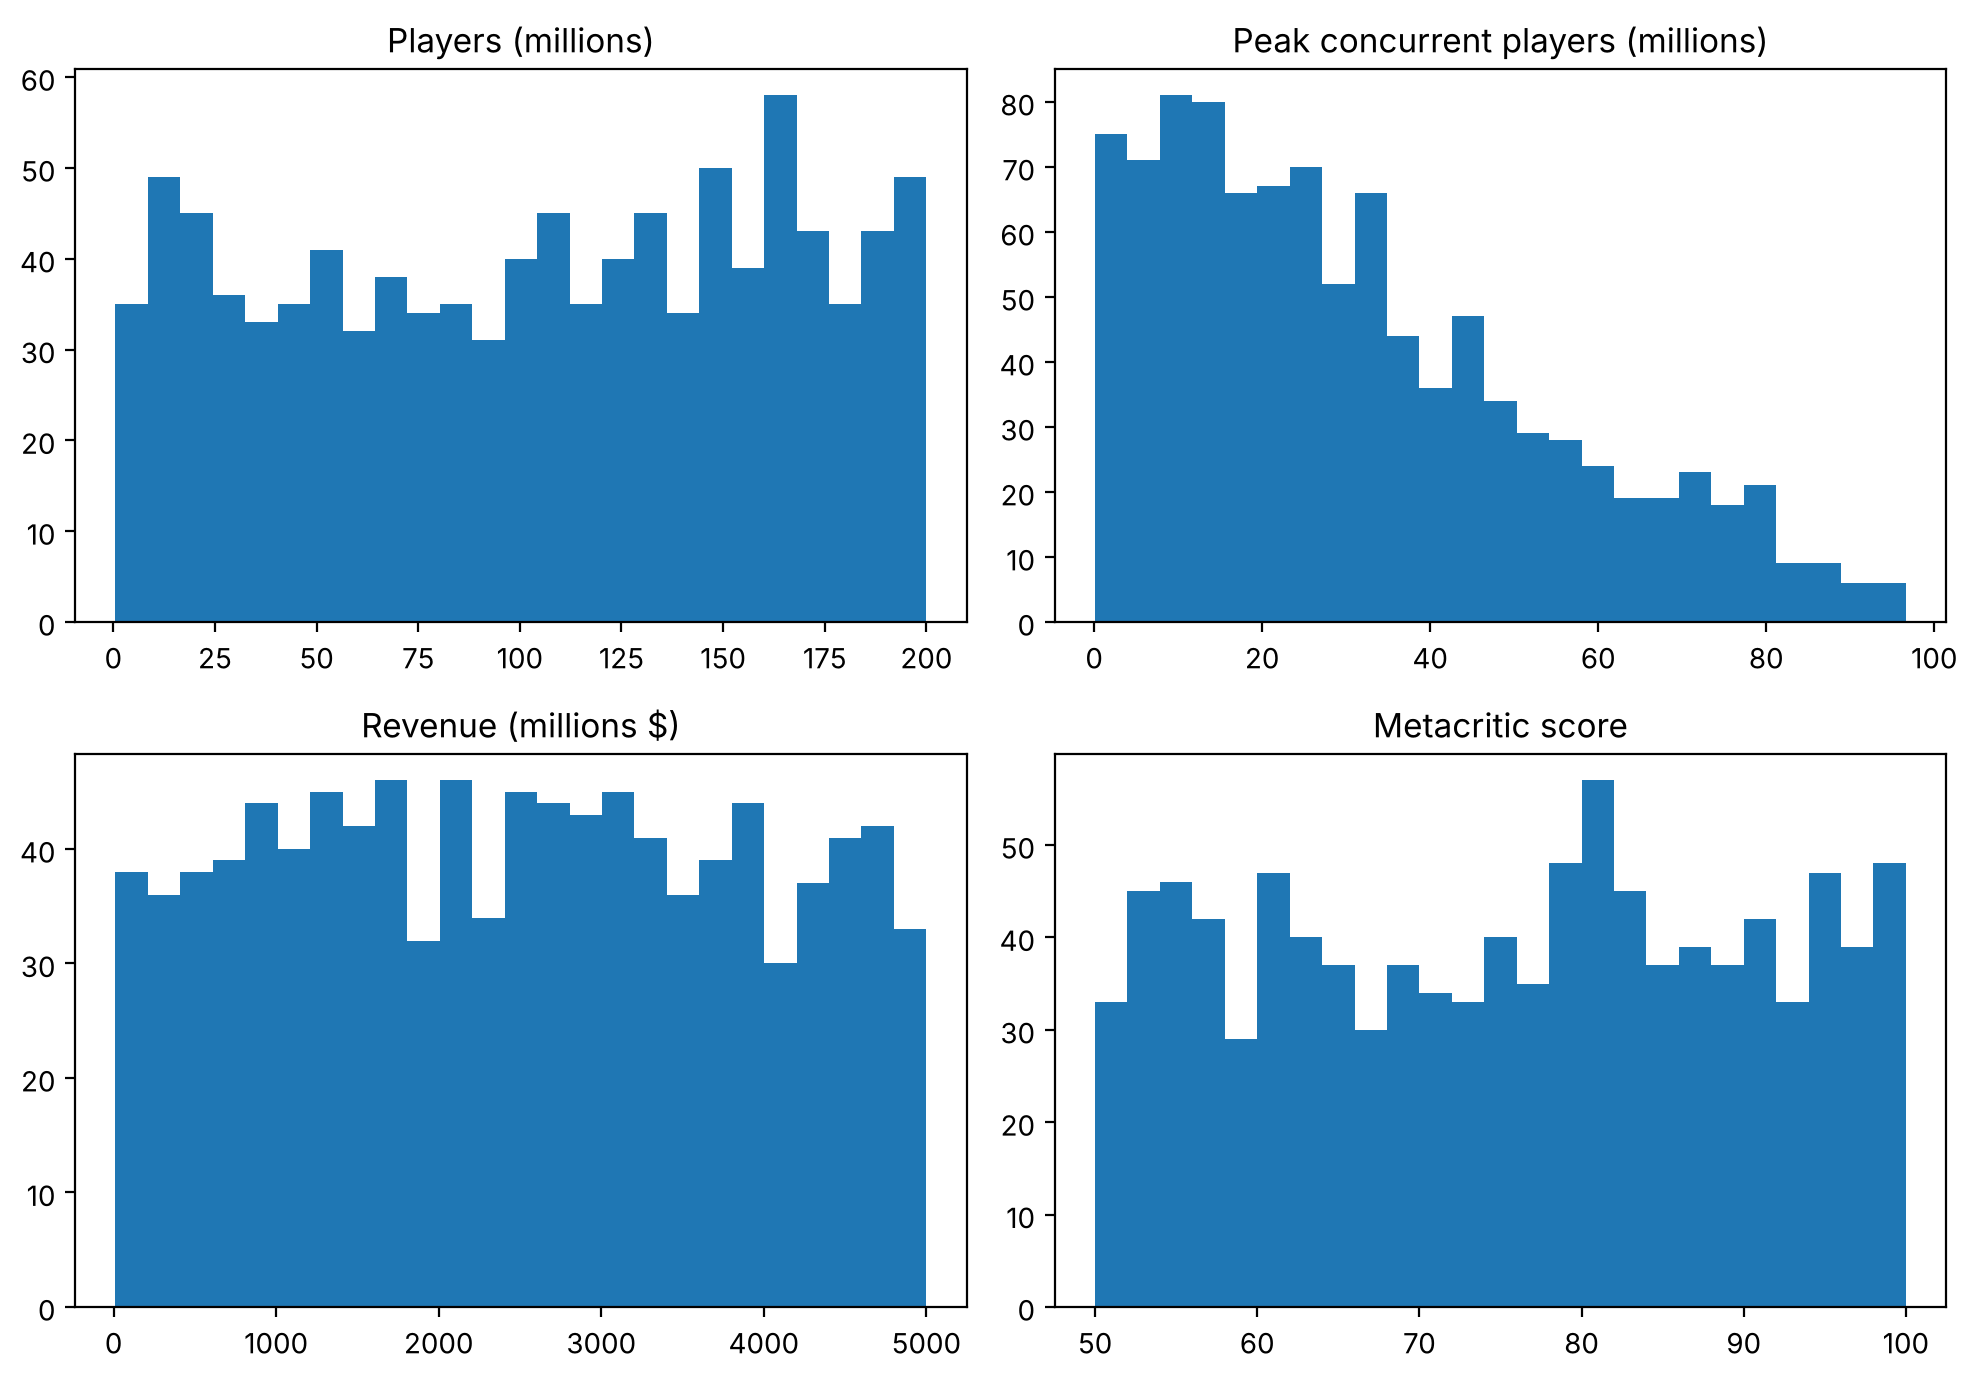

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
axes[0, 0].hist(df['players'], bins=25)
axes[0, 0].set_title('Players (millions)')
axes[0, 1].hist(df['peak'], bins=25)
axes[0, 1].set_title('Peak concurrent players (millions)')
axes[1, 0].hist(df['revenue'], bins=25)
axes[1, 0].set_title('Revenue (millions $)')
axes[1, 1].hist(df['meta'], bins=25)
axes[1, 1].set_title('Metacritic score')
plt.tight_layout()
plt.savefig(figdir + '/1_histograms.png', dpi=120)
plt.show()

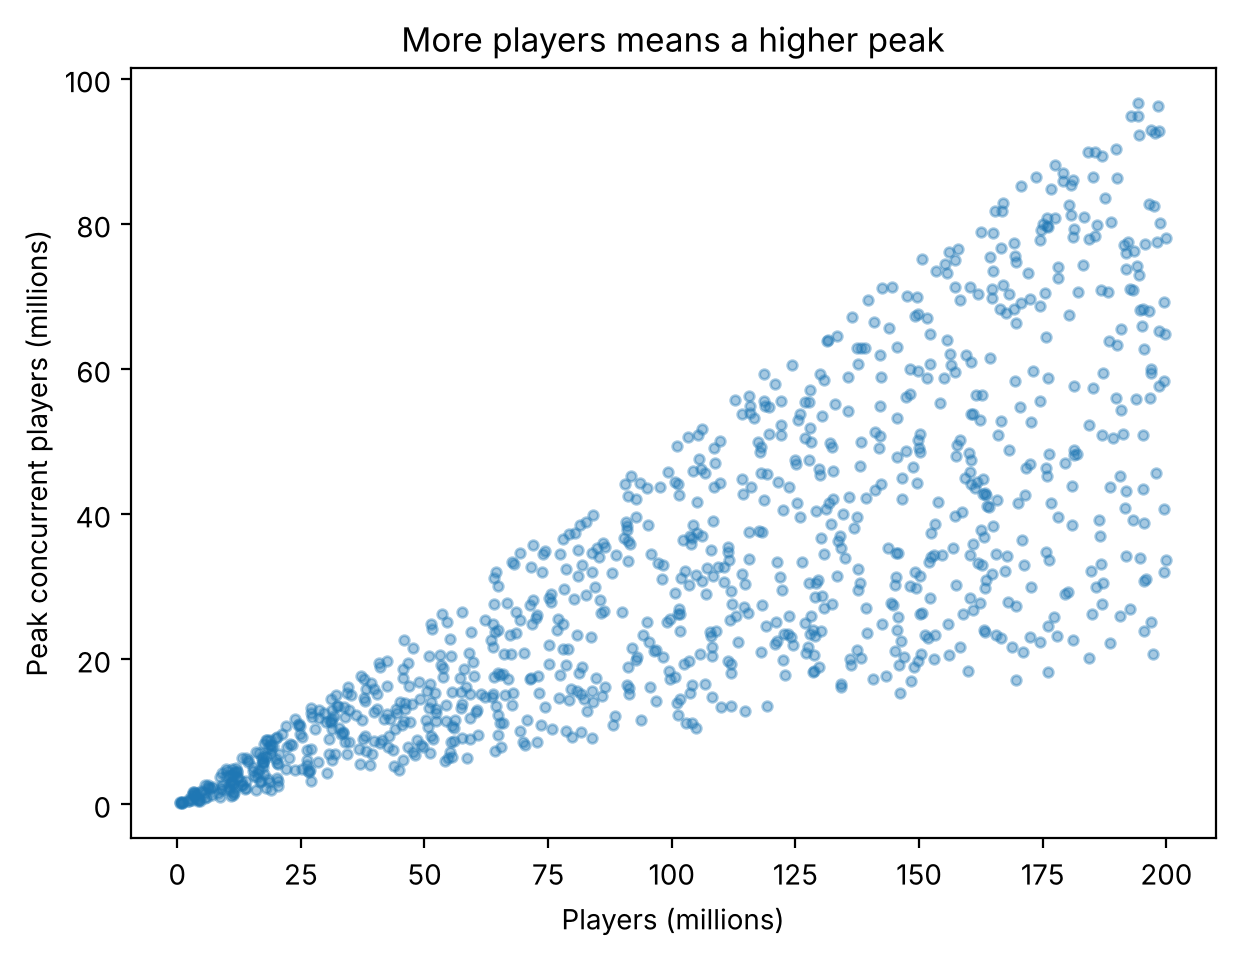

In [8]:
plt.figure(figsize=(7, 5))
plt.scatter(df['players'], df['peak'], alpha=0.4, s=12)
plt.xlabel('Players (millions)')
plt.ylabel('Peak concurrent players (millions)')
plt.title('More players means a higher peak')
plt.savefig(figdir + '/2_players_vs_peak.png', dpi=120)
plt.show()

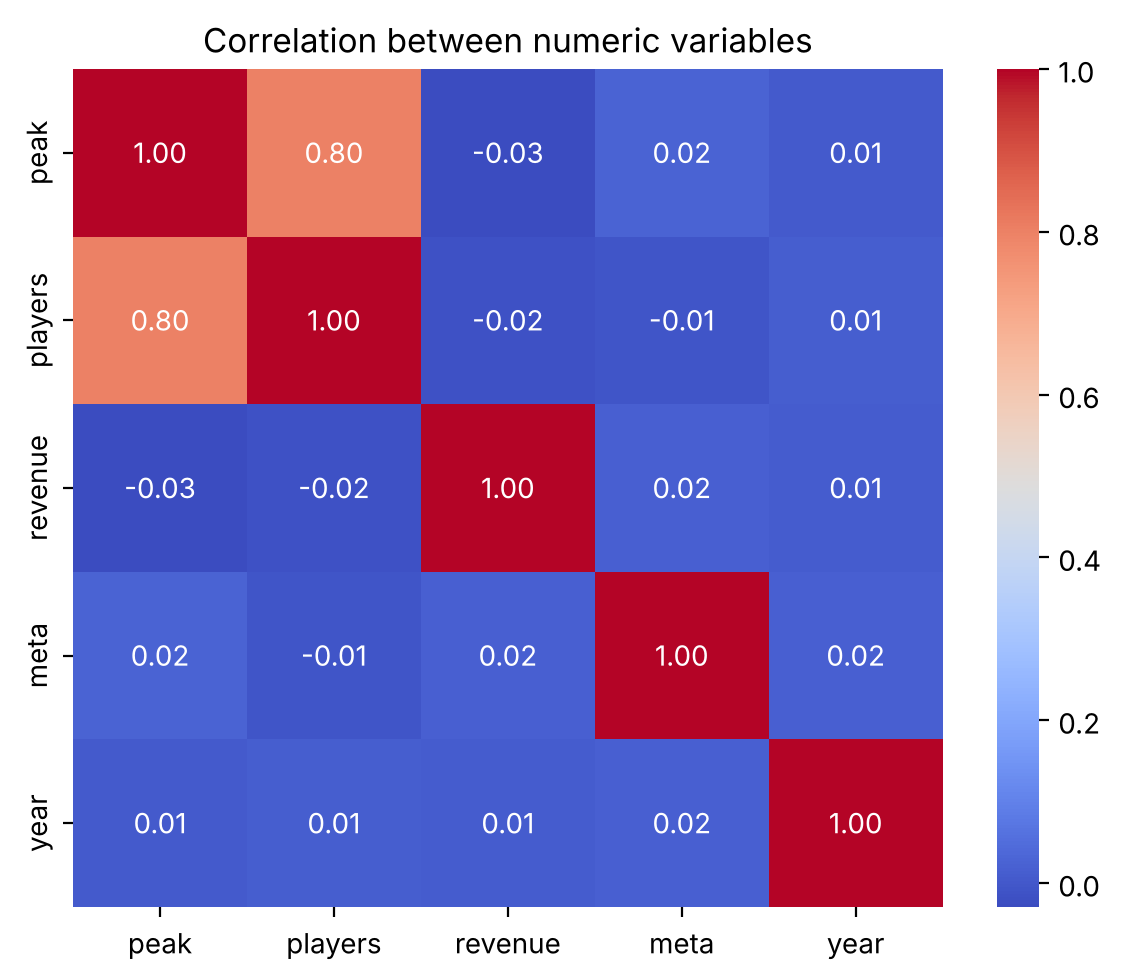

In [9]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[['peak', 'players', 'revenue', 'meta', 'year']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between numeric variables')
plt.tight_layout()
plt.savefig(figdir + '/3_correlation.png', dpi=120)
plt.show()

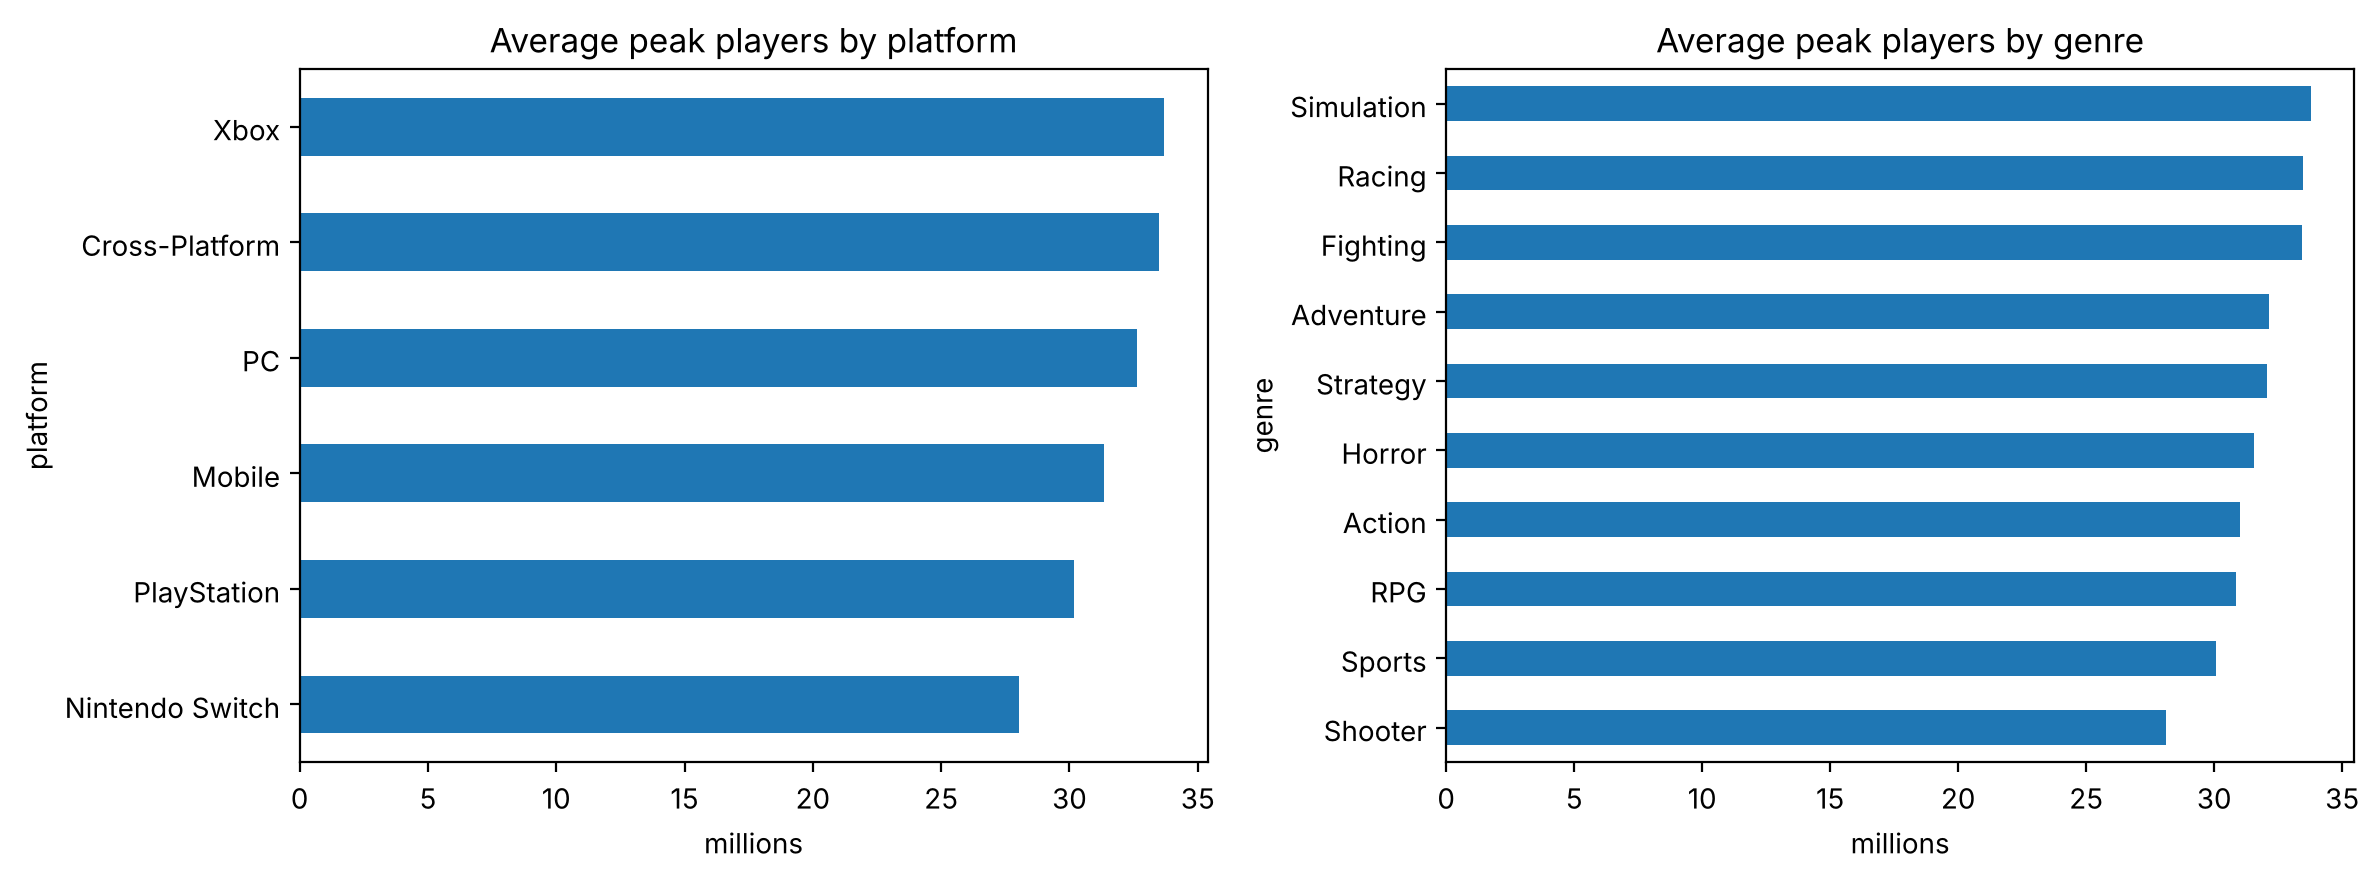

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df.groupby('platform')['peak'].mean().sort_values().plot(kind='barh', ax=axes[0])
axes[0].set_title('Average peak players by platform')
axes[0].set_xlabel('millions')
df.groupby('genre')['peak'].mean().sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_title('Average peak players by genre')
axes[1].set_xlabel('millions')
plt.tight_layout()
plt.savefig(figdir + '/4_platform_genre.png', dpi=120)
plt.show()

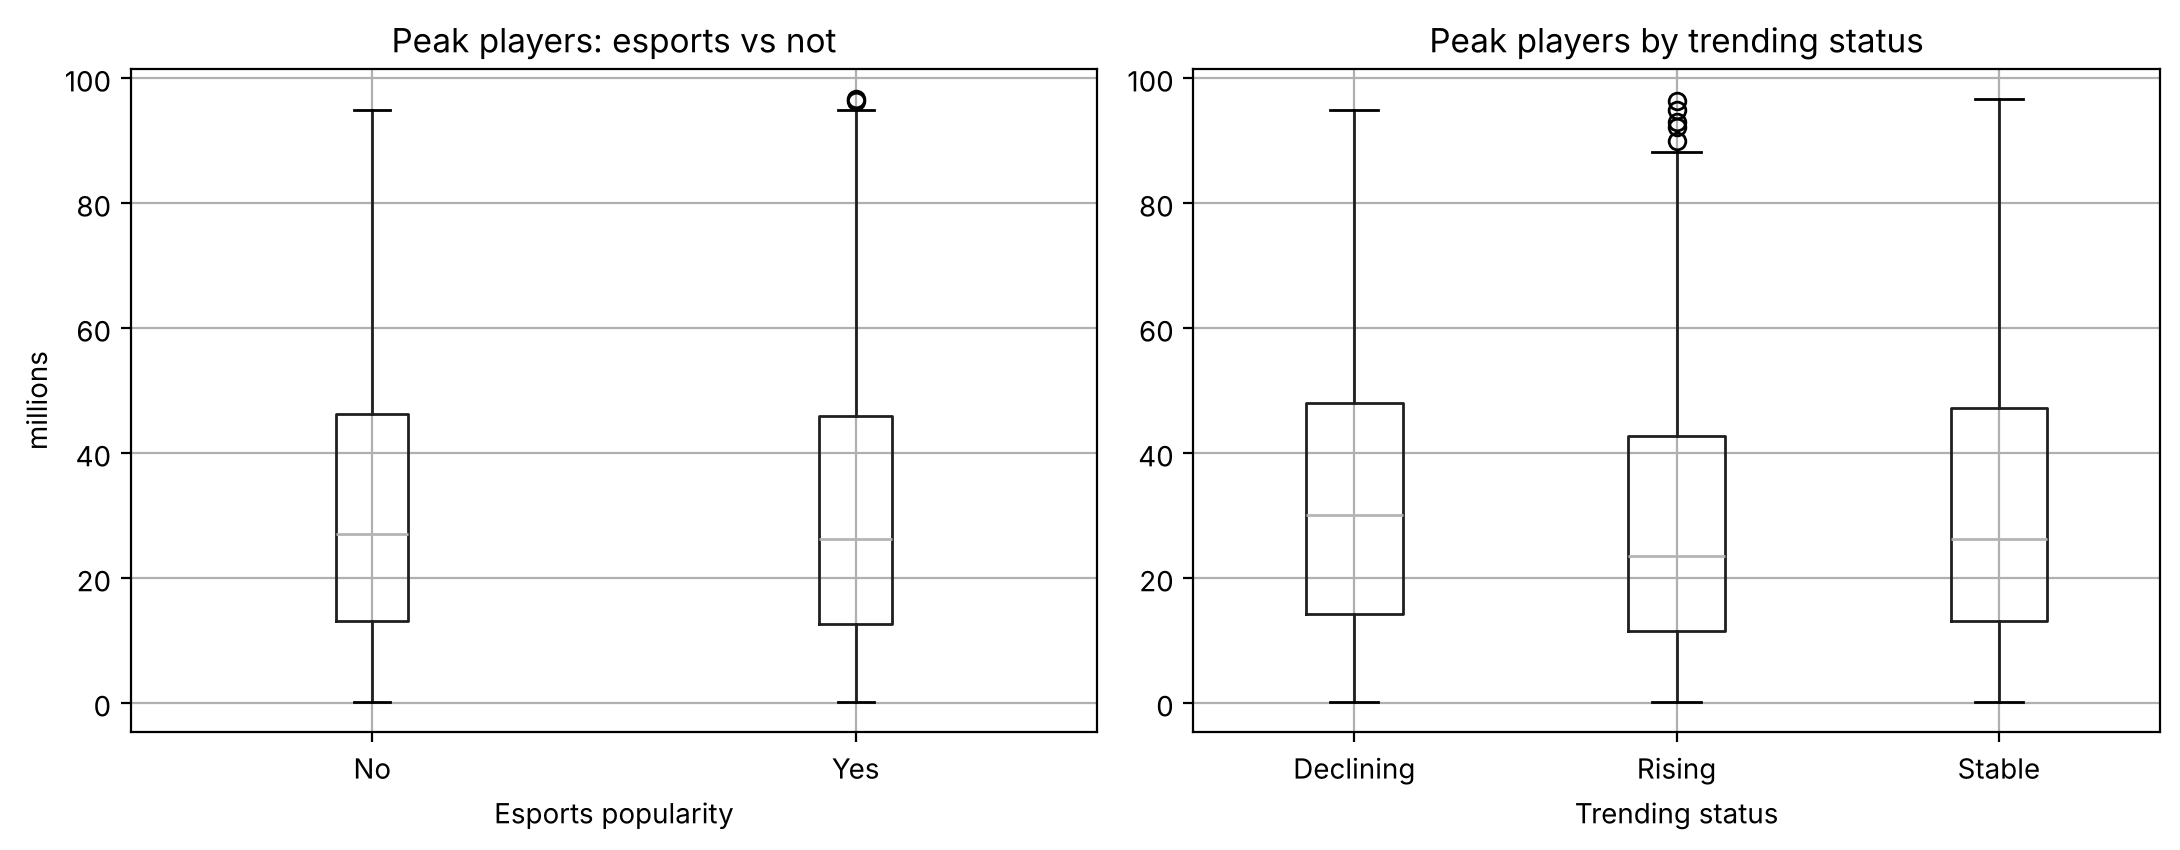

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
df.boxplot(column='peak', by='esports', ax=axes[0])
axes[0].set_title('Peak players: esports vs not')
axes[0].set_xlabel('Esports popularity')
axes[0].set_ylabel('millions')
df.boxplot(column='peak', by='trend', ax=axes[1])
axes[1].set_title('Peak players by trending status')
axes[1].set_xlabel('Trending status')
plt.suptitle('')
plt.tight_layout()
plt.savefig(figdir + '/5_esports_trend.png', dpi=120)
plt.show()

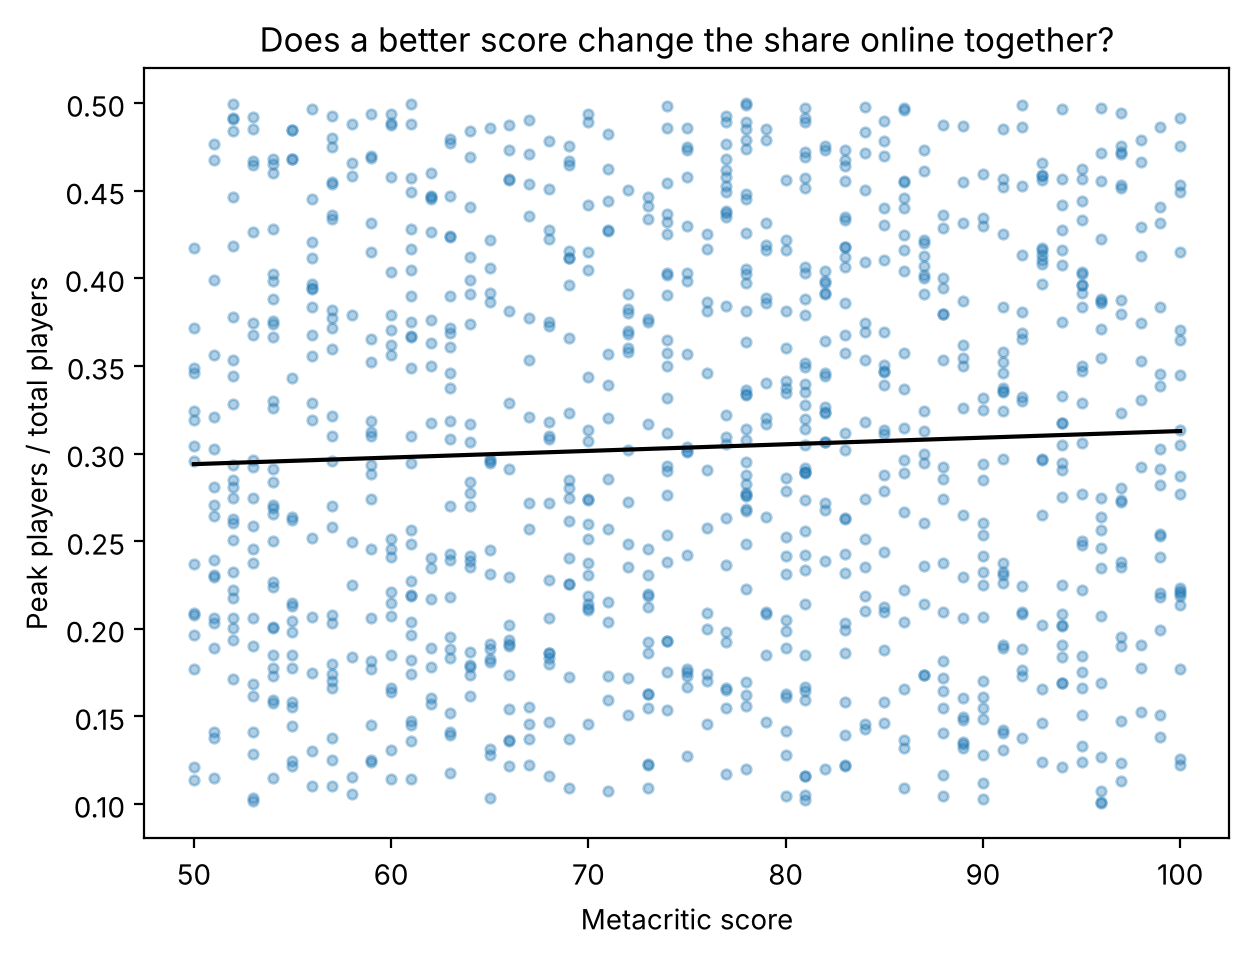

In [12]:
plt.figure(figsize=(7, 5))
plt.scatter(df['meta'], df['peak_ratio'], alpha=0.35, s=12)
m, b = np.polyfit(df['meta'], df['peak_ratio'], 1)
xs = np.array([50, 100])
plt.plot(xs, m * xs + b, color='black')
plt.xlabel('Metacritic score')
plt.ylabel('Peak players / total players')
plt.title('Does a better score change the share online together?')
plt.savefig(figdir + '/6_meta_vs_ratio.png', dpi=120)
plt.show()

The scatter plot of players against peak players is the only chart with a clear pattern. The boxplots and bar charts show that platforms, genres, esports and trending status all look very similar, and the last chart shows that the share of players online together hardly moves with the Metacritic score (the line is almost flat, slightly upward).

## 5. Why I did not use revenue as the target

My first idea was to predict revenue, since that is the obvious business number. I tried it with all the other variables first.

In [13]:
rev = smf.ols('revenue ~ players + peak + meta + year + C(esports) + C(platform) + C(genre) + C(trend)', data=df).fit()
print('R-squared:', round(rev.rsquared, 4))
print('Adjusted R-squared:', round(rev.rsquared_adj, 4))
print('F-test p-value:', round(rev.f_pvalue, 3))

R-squared: 0.0116
Adjusted R-squared: -0.0096
F-test p-value: 0.952


R-squared is only about 1% and adjusted R-squared is negative, so none of these variables explain revenue. It would not be sensible to base a decision on that model. Peak concurrent players, on the other hand, clearly depends on total players, so I use it as my dependent variable.

## 6. Multiple linear regression without interaction (Model 1)

Dependent variable: peak concurrent players.
Independent variables: players, Metacritic score, revenue, release year (numeric) and esports, platform, genre, trending status (categorical, turned into dummies by statsmodels).

I subtracted the mean from players and Metacritic first (`players_c`, `meta_c`). This does not change the fit, but it makes the interaction in Model 2 easier to read.

In [14]:
df['players_c'] = df['players'] - df['players'].mean()
df['meta_c'] = df['meta'] - df['meta'].mean()

f1 = 'peak ~ players_c + meta_c + revenue + year + C(esports) + C(platform) + C(genre) + C(trend)'
model1 = smf.ols(f1, data=df).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:                   peak   R-squared:                       0.646
Model:                            OLS   Adj. R-squared:                  0.639
Method:                 Least Squares   F-statistic:                     85.04
Date:                Thu, 26 Nov 2026   Prob (F-statistic):          1.32e-203
Time:                        06:23:26   Log-Likelihood:                -4035.5
No. Observations:                1000   AIC:                             8115.
Df Residuals:                     978   BIC:                             8223.
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

## 7. Multiple linear regression with interaction (Model 2)

The idea: if a game is well reviewed, people may play it at the same time more (friends join, events, word of mouth), so each extra player might add more to the peak. This means the effect of players on peak could depend on the Metacritic score, so I add `players_c * meta_c`.

Before settling on this, I tried the interaction of players with esports, platform, genre and trending status as well. I only keep the one with Metacritic.

In [15]:
for term in ['players_c:C(esports)', 'players_c:C(platform)', 'players_c:C(genre)', 'players_c:C(trend)', 'players_c:meta_c']:
    m = smf.ols(f1 + ' + ' + term, data=df).fit()
    p = m.compare_f_test(model1)[1]
    print(term.ljust(24), 'adj R2 =', round(m.rsquared_adj, 4), ' p-value vs model 1 =', round(p, 3))

players_c:C(esports)     adj R2 = 0.6383  p-value vs model 1 = 0.591
players_c:C(platform)    adj R2 = 0.639  p-value vs model 1 = 0.291
players_c:C(genre)       adj R2 = 0.6385  p-value vs model 1 = 0.444
players_c:C(trend)       adj R2 = 0.638  p-value vs model 1 = 0.725
players_c:meta_c         adj R2 = 0.6397  p-value vs model 1 = 0.042


In [16]:
f2 = f1 + ' + players_c:meta_c'
model2 = smf.ols(f2, data=df).fit()
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                   peak   R-squared:                       0.648
Model:                            OLS   Adj. R-squared:                  0.640
Method:                 Least Squares   F-statistic:                     81.62
Date:                Thu, 26 Nov 2026   Prob (F-statistic):          1.59e-203
Time:                        06:23:26   Log-Likelihood:                -4033.4
No. Observations:                1000   AIC:                             8113.
Df Residuals:                     977   BIC:                             8226.
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

## 8. Model comparison

In [17]:
# 5-fold cross validation to see how well each model predicts unseen data
def cv_rmse(formula):
    errors = []
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    for train_idx, test_idx in kf.split(df):
        train = df.iloc[train_idx]
        test = df.iloc[test_idx]
        m = smf.ols(formula, data=train).fit()
        pred = m.predict(test)
        errors.append(np.sqrt(np.mean((test['peak'] - pred) ** 2)))
    return np.mean(errors)

comparison = pd.DataFrame({
    'Model 1': [model1.rsquared, model1.rsquared_adj, model1.aic, model1.bic, np.sqrt(model1.mse_resid), cv_rmse(f1)],
    'Model 2': [model2.rsquared, model2.rsquared_adj, model2.aic, model2.bic, np.sqrt(model2.mse_resid), cv_rmse(f2)]},
    index=['R-squared', 'Adjusted R-squared', 'AIC', 'BIC', 'Residual std error', 'CV RMSE (5-fold)'])
print(comparison.round(4))

f_val, p_val, df_diff = model2.compare_f_test(model1)
print()
print('F-test, model 2 vs model 1: F =', round(f_val, 2), ', p =', round(p_val, 4))

                      Model 1    Model 2
R-squared              0.6461     0.6476
Adjusted R-squared     0.6385     0.6397
AIC                 8115.0492  8112.8067
BIC                 8223.0198  8225.6851
Residual std error    13.8420    13.8198
CV RMSE (5-fold)      14.0543    14.0247

F-test, model 2 vs model 1: F = 4.15 , p = 0.0418


In [18]:
coefs = pd.DataFrame({'Model 1 coef': model1.params, 'Model 1 p': model1.pvalues,
                      'Model 2 coef': model2.params, 'Model 2 p': model2.pvalues})
coefs.loc[['players_c', 'meta_c', 'players_c:meta_c', 'revenue', 'year', 'C(esports)[T.Yes]']].round(4)

,Model 1 coef,Model 1 p,Model 2 coef,Model 2 p
players_c,0.3122,0.0000,0.3125,0.0000
meta_c,0.0408,0.1775,0.0389,0.1987
players_c:meta_c,NaN,NaN,0.0011,0.0418
revenue,-0.0003,0.3351,-0.0003,0.3501
year,0.0005,0.9935,0.0045,0.9433
C(esports)[T.Yes],-0.3721,0.6748,-0.4182,0.6368


Metacritic 60 -> 0.297
Metacritic 75 -> 0.313
Metacritic 90 -> 0.328


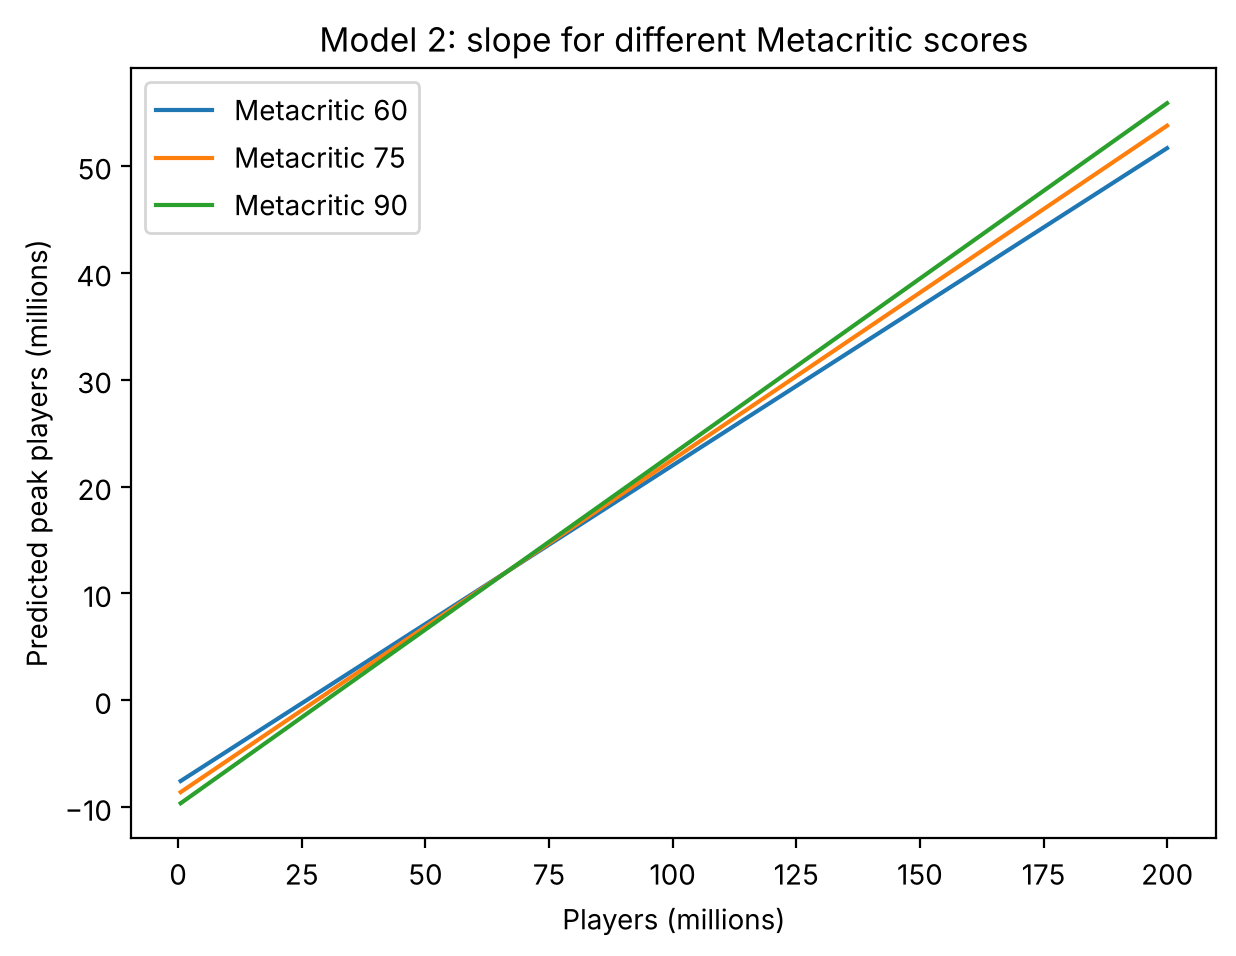

In [19]:
# what the interaction means: extra peak players for every extra 1 million players
b = model2.params
for score in [60, 75, 90]:
    slope = b['players_c'] + b['players_c:meta_c'] * (score - df['meta'].mean())
    print('Metacritic', score, '->', round(slope, 3))

x = np.linspace(df['players'].min(), df['players'].max(), 50)
plt.figure(figsize=(7, 5))
for score in [60, 75, 90]:
    xc = x - df['players'].mean()
    mc = score - df['meta'].mean()
    y = b['Intercept'] + b['players_c'] * xc + b['meta_c'] * mc + b['players_c:meta_c'] * xc * mc
    plt.plot(x, y, label='Metacritic ' + str(score))
plt.xlabel('Players (millions)')
plt.ylabel('Predicted peak players (millions)')
plt.title('Model 2: slope for different Metacritic scores')
plt.legend()
plt.savefig(figdir + '/7_interaction.png', dpi=120)
plt.show()

highest VIF in model 1: 1.75
Breusch-Pagan p-value: 9.87843612530752e-60


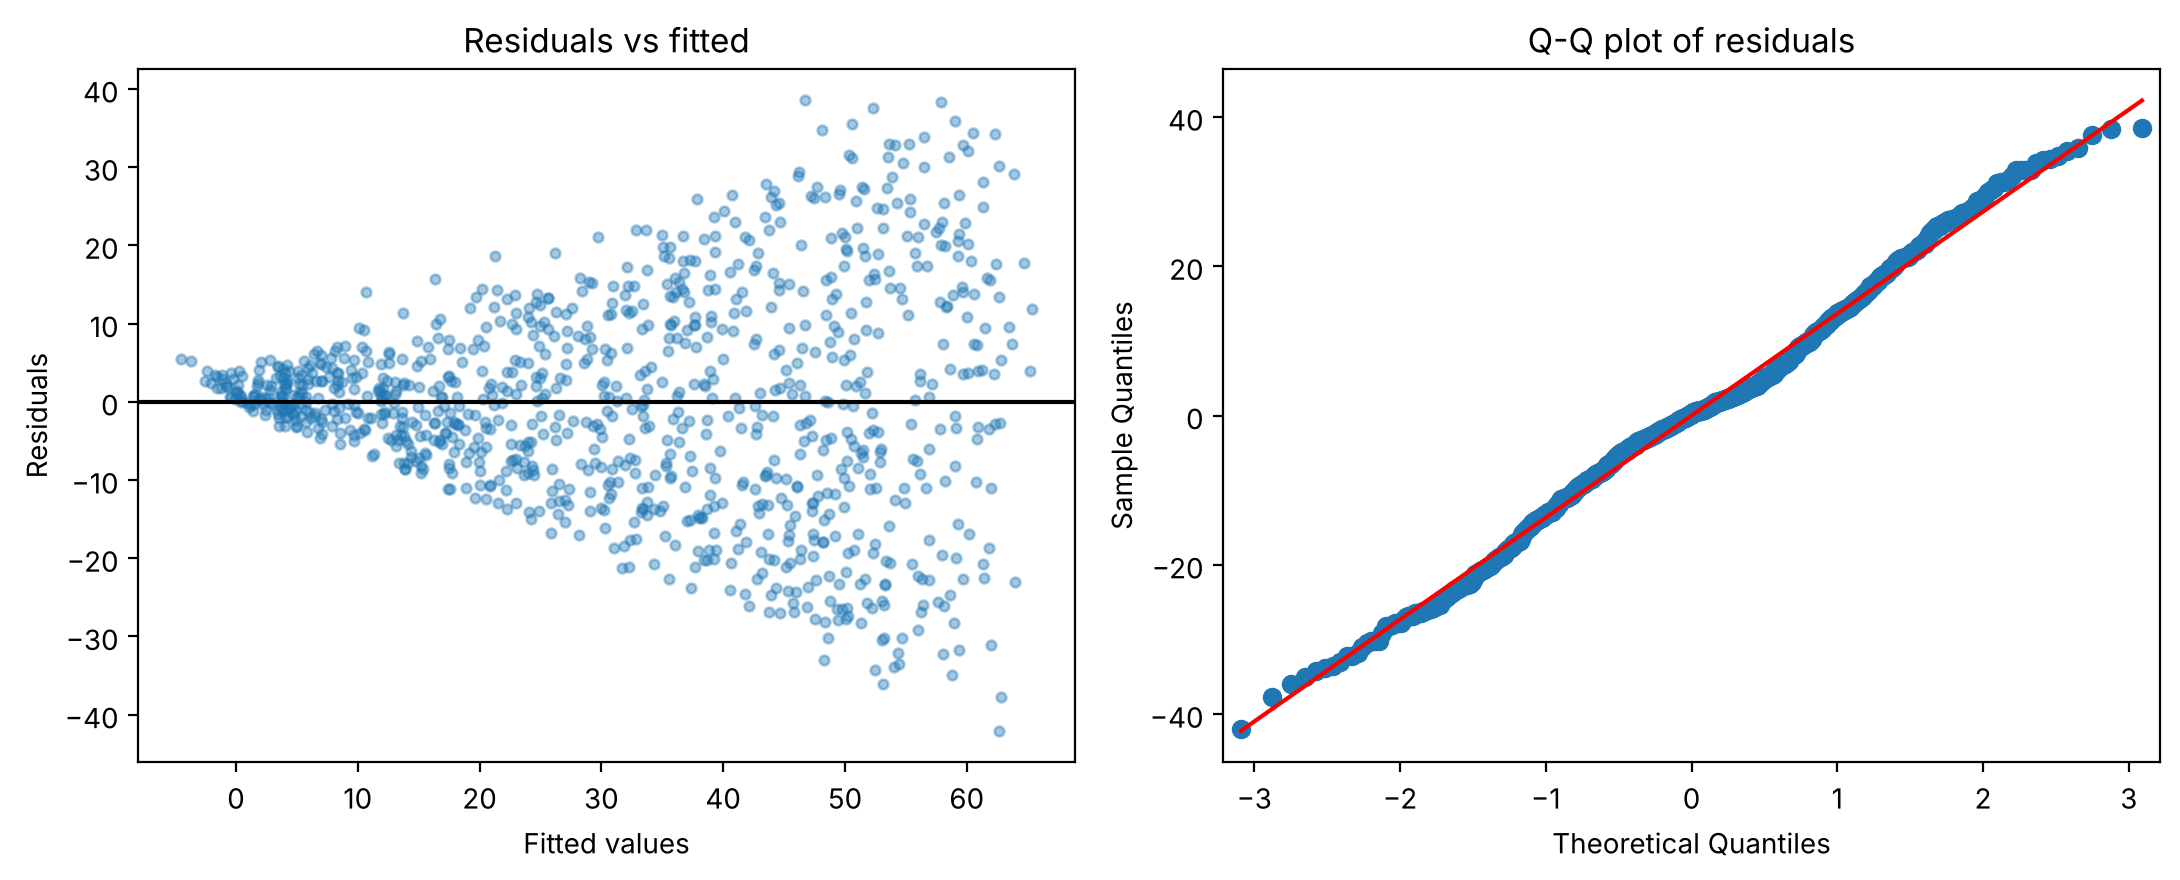

In [20]:
# checking the assumptions
vif = [variance_inflation_factor(model1.model.exog, i) for i in range(1, model1.model.exog.shape[1])]
print('highest VIF in model 1:', round(max(vif), 2))

bp = het_breuschpagan(model2.resid, model2.model.exog)
print('Breusch-Pagan p-value:', bp[1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(model2.fittedvalues, model2.resid, alpha=0.4, s=12)
axes[0].axhline(0, color='black')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs fitted')
sm.qqplot(model2.resid, line='s', ax=axes[1])
axes[1].set_title('Q-Q plot of residuals')
plt.tight_layout()
plt.savefig(figdir + '/8_residuals.png', dpi=120)
plt.show()

In [21]:
# same models with robust (HC3) standard errors, because of the Breusch-Pagan result
robust2 = smf.ols(f2, data=df).fit(cov_type='HC3')
print('interaction coefficient:', round(robust2.params['players_c:meta_c'], 5))
print('classical p-value:', round(model2.pvalues['players_c:meta_c'], 3))
print('robust p-value:', round(robust2.pvalues['players_c:meta_c'], 3))
print()
print('95% range for prediction error: +/-', round(1.96 * np.sqrt(model1.mse_resid), 1), 'million')

interaction coefficient: 0.00105
classical p-value: 0.042
robust p-value: 0.056

95% range for prediction error: +/- 27.1 million


## 9. What the results mean

**Model 1.** Total players is the only variable that really matters. Every extra 1 million players adds about 0.31 million to the peak (p < 0.001). The model explains 64.6% of the variation in peak players (adjusted R-squared 63.9%). Metacritic, revenue, release year, esports, genre and trending status are all not significant. PlayStation is slightly lower than the base platform (about 2.7 million, p around 0.07 to 0.08), which is only weak evidence.

**Model 2.** The interaction coefficient is 0.00105. In simple terms, an extra million players adds about 0.297 million to the peak for a game with Metacritic 60, 0.313 million at 75 and 0.328 million at 90. So better rated games get slightly more simultaneous players per player. The p-value is 0.042, which looks significant, but the residual plot and the Breusch-Pagan test show the errors get bigger for bigger games. With robust standard errors the p-value becomes 0.056, so it is no longer under 5%. I also tried five interactions, so one borderline result could easily be luck.

**Comparing the two.** R-squared goes from 0.6461 to 0.6476 and adjusted R-squared from 0.6385 to 0.6397, a tiny gain. AIC prefers Model 2 (8112.8 vs 8115.0) but BIC prefers Model 1 (8223.0 vs 8225.7), and cross-validated RMSE barely changes (14.05 to 14.03). I would go with Model 1 because it is simpler and almost as good. The interaction is an interesting hint, not a confirmed result.

**What a manager can do with this**
- Plan server capacity at roughly 30% of the forecast number of players, and keep a safety buffer. The typical error is about 13.8 million, so the 95% range is around plus or minus 27 million. Bigger games have bigger errors, so blockbusters need a bigger buffer.
- There is no evidence that genre, platform, esports or trending status change the share of players online together, so one common rule is fine for now.
- Even if the quality effect is real, a 15 point higher Metacritic score only raises the peak per player by about 5%, which is not a big reason to spend more. It should be checked with real data first.
- Revenue cannot be explained by anything in this dataset, so revenue forecasts need other data like pricing and conversion.

## 10. SQL analysis

I loaded the csv into a SQLite table called `games` and added two small lookup tables for the joins: `dim_platform` (platform type) and `dim_developer` (country of the developer's headquarters). The same queries are saved in `sql/02_queries.sql`.

In [22]:
schema = """-- Two small lookup tables used for the joins. The main table (games) is loaded from the csv.
DROP TABLE IF EXISTS dim_platform;
CREATE TABLE dim_platform (
    platform       TEXT PRIMARY KEY,
    platform_type  TEXT NOT NULL            -- my own grouping
);
INSERT INTO dim_platform VALUES
    ('PC','PC'),('PlayStation','Console'),('Xbox','Console'),
    ('Nintendo Switch','Console'),('Mobile','Mobile'),('Cross-Platform','Cross-Platform');

DROP TABLE IF EXISTS dim_developer;
CREATE TABLE dim_developer (
    developer   TEXT PRIMARY KEY,
    hq_country  TEXT NOT NULL               -- added from public info
);
INSERT INTO dim_developer VALUES
    ('Capcom','Japan'),('Bandai Namco','Japan'),('Sony','Japan'),('Square Enix','Japan'),
    ('Nintendo','Japan'),('Microsoft','USA'),('EA','USA'),('Activision','USA'),
    ('Rockstar','USA'),('Ubisoft','France');
"""

In [23]:
games = raw.copy()
games.columns = ['title', 'genre', 'platform', 'release_year', 'developer', 'revenue_musd',
                 'players_m', 'peak_ccu_m', 'metacritic', 'esports', 'trending']
games.insert(0, 'game_id', range(1, len(games) + 1))

con = sqlite3.connect(':memory:')
games.to_sql('games', con, index=False)
con.executescript(schema)

def q(sql):
    return pd.read_sql(sql, con)

q("SELECT name FROM sqlite_master WHERE type='table'")

,name
0,games
1,dim_platform
2,dim_developer


### Q1: Overall summary of the data

In [24]:
q("""
SELECT COUNT(*) AS records, COUNT(DISTINCT title) AS distinct_titles,
       ROUND(SUM(revenue_musd)/1000,1) AS total_revenue_bn,
       ROUND(AVG(revenue_musd),0) AS avg_revenue_musd,
       ROUND(AVG(players_m),1) AS avg_players_m,
       ROUND(AVG(peak_ccu_m),1) AS avg_peak_ccu_m,
       ROUND(AVG(metacritic),1) AS avg_metacritic
FROM games;
""")

,records,distinct_titles,total_revenue_bn,avg_revenue_musd,avg_players_m,avg_peak_ccu_m,avg_metacritic
0,1000,50,2483.0,2483.0,103.5,31.6,75.0


There are 50 titles across 1,000 records. An average record has about 103 million players and a peak of about 32 million.

### Q2: Genre comparison

In [25]:
q("""
SELECT genre, COUNT(*) AS games, ROUND(AVG(revenue_musd),0) AS avg_revenue_musd,
       ROUND(AVG(players_m),1) AS avg_players_m,
       ROUND(AVG(peak_ccu_m),1) AS avg_peak_ccu_m,
       ROUND(AVG(peak_ccu_m*1.0/players_m),3) AS peak_to_player_ratio
FROM games GROUP BY genre ORDER BY avg_revenue_musd DESC;
""")

,genre,games,avg_revenue_musd,avg_players_m,avg_peak_ccu_m,peak_to_player_ratio
0,RPG,78,2716.0,97.4,30.8,0.331
1,Fighting,103,2650.0,107.3,33.4,0.305
2,Simulation,87,2555.0,111.9,33.8,0.306
3,Horror,96,2524.0,103.0,31.6,0.295
4,Adventure,87,2502.0,100.0,32.1,0.310
5,Racing,95,2460.0,106.9,33.5,0.301
6,Strategy,116,2440.0,106.7,32.1,0.302
7,Shooter,100,2429.0,96.6,28.1,0.291
8,Action,122,2388.0,107.0,31.0,0.294
9,Sports,116,2284.0,97.1,30.1,0.308


RPG earns the most on average, but its peak is only average. Simulation and Racing have the highest peaks. The differences between genres are small.

### Q3: Platforms with more than 150 games

In [26]:
q("""
SELECT platform, COUNT(*) AS games, ROUND(AVG(metacritic),1) AS avg_metacritic,
       ROUND(AVG(revenue_musd),0) AS avg_revenue_musd
FROM games GROUP BY platform HAVING COUNT(*) > 150 ORDER BY games DESC;
""")

,platform,games,avg_metacritic,avg_revenue_musd
0,PlayStation,175,74.2,2375.0
1,PC,174,76.6,2450.0
2,Cross-Platform,168,74.6,2522.0
3,Xbox,167,75.1,2463.0
4,Nintendo Switch,158,73.5,2577.0
5,Mobile,158,75.8,2526.0


All six platforms have a similar number of games and similar scores, so no platform stands out.

### Q4: Revenue by developer country (join)

In [27]:
q("""
SELECT d.hq_country, COUNT(*) AS games, COUNT(DISTINCT g.developer) AS developers,
       ROUND(SUM(g.revenue_musd)/1000,1) AS total_revenue_bn,
       ROUND(AVG(g.metacritic),1) AS avg_metacritic
FROM games g JOIN dim_developer d ON g.developer = d.developer
GROUP BY d.hq_country ORDER BY total_revenue_bn DESC;
""")

,hq_country,games,developers,total_revenue_bn,avg_metacritic
0,Japan,483,5,1235.4,75.5
1,USA,414,4,1014.5,74.8
2,France,103,1,233.2,73.3


Japanese developers bring in the most revenue, but they also make up half of the ten developers. Review scores are almost the same in all three countries.

### Q5: Platform type summary (join)

In [28]:
q("""
SELECT p.platform_type, COUNT(*) AS games,
       ROUND(AVG(g.players_m),1) AS avg_players_m,
       ROUND(AVG(g.peak_ccu_m),1) AS avg_peak_ccu_m,
       ROUND(100.0*SUM(CASE WHEN g.esports='Yes' THEN 1 ELSE 0 END)/COUNT(*),1) AS pct_esports
FROM games g JOIN dim_platform p ON g.platform = p.platform
GROUP BY p.platform_type ORDER BY avg_peak_ccu_m DESC;
""")

,platform_type,games,avg_players_m,avg_peak_ccu_m,pct_esports
0,Cross-Platform,168,108.1,33.5,51.2
1,PC,174,106.2,32.7,52.3
2,Mobile,158,98.7,31.3,50.6
3,Console,500,102.5,30.7,50.0


Cross-platform and PC games have the highest average peak and consoles the lowest. Around half the games on every platform type have esports.

### Q6: Esports vs non-esports games

In [29]:
q("""
SELECT esports, COUNT(*) AS games, ROUND(AVG(revenue_musd),0) AS avg_revenue_musd,
       ROUND(AVG(players_m),1) AS avg_players_m,
       ROUND(AVG(peak_ccu_m*1.0/players_m),3) AS peak_to_player_ratio
FROM games GROUP BY esports;
""")

,esports,games,avg_revenue_musd,avg_players_m,peak_to_player_ratio
0,No,493,2462.0,104.4,0.304
1,Yes,507,2503.0,102.6,0.303


Esports and non-esports games have almost the same revenue and the same peak-to-player ratio (about 0.30), so esports alone does not mean more people online together.

### Q7: Games grouped by Metacritic score band

In [30]:
q("""
SELECT CASE WHEN metacritic >= 85 THEN '1. Acclaimed (85+)'
            WHEN metacritic >= 70 THEN '2. Good (70-84)'
            WHEN metacritic >= 60 THEN '3. Mixed (60-69)'
            ELSE '4. Weak (<60)' END AS quality_band,
       COUNT(*) AS games, ROUND(AVG(players_m),1) AS avg_players_m,
       ROUND(AVG(peak_ccu_m),1) AS avg_peak_ccu_m,
       ROUND(AVG(peak_ccu_m*1.0/players_m),3) AS peak_to_player_ratio,
       ROUND(AVG(revenue_musd),0) AS avg_revenue_musd
FROM games GROUP BY quality_band ORDER BY quality_band;
""")

,quality_band,games,avg_players_m,avg_peak_ccu_m,peak_to_player_ratio,avg_revenue_musd
0,1. Acclaimed (85+),306,101.9,31.7,0.304,2507.0
1,2. Good (70-84),308,103.6,32.0,0.314,2469.0
2,3. Mixed (60-69),191,104.0,30.9,0.296,2546.0
3,4. Weak (<60),195,105.3,31.4,0.293,2405.0


There is no clear pattern between score band and revenue or peak ratio. This is consistent with the regression finding only a very small effect of quality.

### Q8: Top 3 revenue games in each genre

In [31]:
q("""
SELECT genre, title, platform, release_year, revenue_musd, rn FROM (
    SELECT genre, title, platform, release_year, revenue_musd,
           ROW_NUMBER() OVER (PARTITION BY genre ORDER BY revenue_musd DESC) AS rn
    FROM games) WHERE rn <= 3 ORDER BY genre, rn;
""")

,genre,title,platform,release_year,revenue_musd,rn
0,Action,Zombie Outbreak 3,PlayStation,2003,4992.70,1
1,Action,Galaxy Raiders 1,Mobile,2002,4940.36,2
2,Action,Galaxy Raiders 4,Mobile,2018,4872.45,3
3,Adventure,Legends of Valor 4,Xbox,2021,4952.49,1
4,Adventure,Neon Speed 3,Cross-Platform,2018,4913.96,2
5,Adventure,Cyber Quest 4,PlayStation,2018,4904.32,3
6,Fighting,Zombie Outbreak 5,Cross-Platform,2016,4884.23,1
7,Fighting,Shadow Realms 5,Nintendo Switch,2015,4829.03,2
8,Fighting,Shadow Realms 1,Nintendo Switch,2013,4824.91,3
9,Horror,Fantasy Rivals 2,Xbox,2010,4993.36,1


The top three games in every genre are all close to the 5 billion revenue ceiling, and a few titles show up in more than one genre.

### Q9: Developers earning above the overall average

In [32]:
q("""
WITH dev AS (
    SELECT developer, COUNT(*) AS games, AVG(revenue_musd) AS avg_rev, AVG(metacritic) AS avg_meta
    FROM games GROUP BY developer)
SELECT developer, games, ROUND(avg_rev,0) AS avg_revenue_musd, ROUND(avg_meta,1) AS avg_metacritic
FROM dev WHERE avg_rev > (SELECT AVG(revenue_musd) FROM games)
ORDER BY avg_rev DESC;
""")

,developer,games,avg_revenue_musd,avg_metacritic
0,Capcom,96,2698.0,76.6
1,Sony,120,2669.0,74.7
2,Nintendo,96,2594.0,74.3
3,Activision,109,2514.0,74.5


Only Capcom, Sony, Nintendo and Activision earn more than the overall average per game.

### Q10: Trend across 5-year release blocks

In [33]:
q("""
SELECT (release_year/5)*5 AS five_year_block, COUNT(*) AS games,
       ROUND(AVG(revenue_musd),0) AS avg_revenue_musd,
       ROUND(AVG(peak_ccu_m),1) AS avg_peak_ccu_m,
       ROUND(AVG(metacritic),1) AS avg_metacritic
FROM games GROUP BY five_year_block ORDER BY five_year_block;
""")

,five_year_block,games,avg_revenue_musd,avg_peak_ccu_m,avg_metacritic
0,2000,183,2539.0,29.4,73.1
1,2005,210,2452.0,32.4,76.2
2,2010,202,2385.0,32.6,76.2
3,2015,217,2560.0,32.8,74.1
4,2020,188,2480.0,30.4,75.2


Average revenue and score stay roughly flat over time. Games from the 2000 and 2020 blocks have slightly lower peaks.

### Q11: Trending status split by esports

In [34]:
q("""
SELECT trending, COUNT(*) AS games,
       SUM(CASE WHEN esports='Yes' THEN 1 ELSE 0 END) AS esports_games,
       SUM(CASE WHEN esports='No' THEN 1 ELSE 0 END) AS non_esports_games,
       ROUND(AVG(revenue_musd),0) AS avg_revenue_musd
FROM games GROUP BY trending ORDER BY games DESC;
""")

,trending,games,esports_games,non_esports_games,avg_revenue_musd
0,Stable,339,178,161,2497.0
1,Rising,335,168,167,2512.0
2,Declining,326,161,165,2438.0


Rising, stable and declining games all have a similar esports split. Declining games earn the least.

### Q12: Genre and platform type with the highest average peak players

In [35]:
q("""
SELECT g.genre, p.platform_type, COUNT(*) AS games, ROUND(AVG(g.peak_ccu_m),1) AS avg_peak_ccu_m
FROM games g JOIN dim_platform p ON g.platform = p.platform
GROUP BY g.genre, p.platform_type HAVING COUNT(*) >= 15
ORDER BY avg_peak_ccu_m DESC LIMIT 8;
""")

,genre,platform_type,games,avg_peak_ccu_m
0,Sports,PC,19,41.8
1,Simulation,PC,17,39.3
2,Fighting,PC,24,38.0
3,Strategy,Mobile,16,36.1
4,Racing,Mobile,19,35.7
5,Sports,Cross-Platform,21,35.5
6,Racing,Console,46,35.1
7,Action,Cross-Platform,22,34.6


PC versions of Sports, Simulation and Fighting games have the highest average peak, so these are where extra server capacity is most needed.

## 11. Conclusion and limitations

Total players explain about 65% of the variation in peak concurrent players, and nothing else in the data adds much. The simple model is good enough to plan servers at roughly 30% of the player forecast with a safety buffer.

Limitations: the data looks synthetic (revenue is unrelated to everything and group averages are almost identical), so these findings should be checked on real game data before any real spending. Each row is a title-platform-year record rather than a unique game, and the unit of peak players is not given in the source.